# Predicting Next-Year GDP Growth Across Countries

## Exploratory Data Analysis and Statistical Analysis

**Prepared by:** Sukesh  
**Workstream:** EDA and Statistical Analysis

This notebook uses the four prepared country-year dataset splits supplied for the group project. It covers data quality, missingness, country and year coverage, descriptive statistics, distributions, potential outliers, correlations, hypothesis testing and country-level patterns.

The four splits are combined for descriptive EDA. Validation and test observations must not be used to fit preprocessing, select features or tune models.

## Upload and extract project data

This section completes the corresponding EDA and statistical analysis step.

In [1]:
from google.colab import files
import os

print("Please select and upload ALL FOUR CSV files together.")
print("1. GDP_Training_2001_2017.csv")
print("2. GDP_Validation_2018_2019.csv")
print("3. GDP_COVID_2020.csv")
print("4. GDP_Testing_2021_2024.csv")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No files were uploaded. Please select all four CSV files.")

expected_files = {
    "Training": "GDP_Training_2001_2017.csv",
    "Validation": "GDP_Validation_2018_2019.csv",
    "COVID": "GDP_COVID_2020.csv",
    "Testing": "GDP_Testing_2021_2024.csv"
}

# Match uploaded files by their exact filenames (case-insensitive).
uploaded_by_lower_name = {os.path.basename(name).lower(): name for name in uploaded.keys()}

file_paths = {}
missing_files = []

for split, expected_name in expected_files.items():
    uploaded_name = uploaded_by_lower_name.get(expected_name.lower())
    if uploaded_name is None:
        missing_files.append(expected_name)
    else:
        file_paths[split] = os.path.abspath(uploaded_name)

if missing_files:
    raise FileNotFoundError(
        "The following required CSV file(s) were not uploaded:\n- "
        + "\n- ".join(missing_files)
        + "\n\nPlease rerun this cell and select all four CSV files together."
    )

print("\nAll four CSV files were uploaded successfully:")
for split, path in file_paths.items():
    print(f"{split}: {os.path.basename(path)}")

print("\nYou can now continue running the notebook from the next cell.")


Please select and upload ALL FOUR CSV files together.
1. GDP_Training_2001_2017.csv
2. GDP_Validation_2018_2019.csv
3. GDP_COVID_2020.csv
4. GDP_Testing_2021_2024.csv


Saving GDP_COVID_2020.csv to GDP_COVID_2020.csv
Saving GDP_Testing_2021_2024.csv to GDP_Testing_2021_2024.csv
Saving GDP_Training_2001_2017.csv to GDP_Training_2001_2017.csv
Saving GDP_Validation_2018_2019.csv to GDP_Validation_2018_2019.csv

All four CSV files were uploaded successfully:
Training: GDP_Training_2001_2017.csv
Validation: GDP_Validation_2018_2019.csv
COVID: GDP_COVID_2020.csv
Testing: GDP_Testing_2021_2024.csv

You can now continue running the notebook from the next cell.


## Import libraries and load datasets

This section completes the corresponding EDA and statistical analysis step.

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

datasets = {
    split: pd.read_csv(path)
    for split, path in file_paths.items()
}

training = datasets["Training"]
validation = datasets["Validation"]
covid = datasets["COVID"]
testing = datasets["Testing"]

print("All libraries imported and four datasets loaded successfully.")

output_dir = "/content/EDA_Statistical_Outputs"
os.makedirs(output_dir, exist_ok=True)
print("Output folder ready:", output_dir)


All libraries imported and four datasets loaded successfully.
Output folder ready: /content/EDA_Statistical_Outputs


## Dataset dimensions and columns and Sample records and data types

This section completes the corresponding EDA and statistical analysis step.

In [3]:
dataset_summary = pd.DataFrame([
    {"Dataset": name, "Rows": frame.shape[0], "Columns": frame.shape[1]}
    for name, frame in datasets.items()
])
display(dataset_summary)

for name, frame in datasets.items():
    print(f"\n{name} columns:")
    print(frame.columns.tolist())

for name, frame in datasets.items():
    print(f"\n{name} — first five records")
    display(frame.head())
    print(f"{name} — data types and non-null counts")
    frame.info()

,Dataset,Rows,Columns
0,Training,3689,13
1,Validation,434,13
2,COVID,217,13
3,Testing,868,13



Training columns:
['Country Name', 'Country Code', 'Year', 'target_year', 'gdp_growth', 'inflation', 'unemployment', 'trade', 'investment', 'population_growth', 'government_debt', 'current_account', 'next_year_gdp_growth']

Validation columns:
['Country Name', 'Country Code', 'Year', 'target_year', 'gdp_growth', 'inflation', 'unemployment', 'trade', 'investment', 'population_growth', 'government_debt', 'current_account', 'next_year_gdp_growth']

COVID columns:
['Country Name', 'Country Code', 'Year', 'target_year', 'gdp_growth', 'inflation', 'unemployment', 'trade', 'investment', 'population_growth', 'government_debt', 'current_account', 'next_year_gdp_growth']

Testing columns:
['Country Name', 'Country Code', 'Year', 'target_year', 'gdp_growth', 'inflation', 'unemployment', 'trade', 'investment', 'population_growth', 'government_debt', 'current_account', 'next_year_gdp_growth']

Training — first five records


,Country Name,Country Code,Year,target_year,gdp_growth,inflation,unemployment,trade,investment,population_growth,government_debt,current_account,next_year_gdp_growth
0,Aruba,ABW,2000,2001,7.622921,4.044021,NaN,145.072880,25.494114,1.030817,38.613,11.345,4.182002
1,Aruba,ABW,2001,2002,4.182002,2.883604,NaN,140.391109,23.999178,0.935033,44.326,16.350,-0.944953
2,Aruba,ABW,2002,2003,-0.944953,3.315247,NaN,133.230771,26.629980,0.692052,47.079,-16.996,1.110505
3,Aruba,ABW,2003,2004,1.110505,3.656365,NaN,132.794291,28.881704,1.138229,40.848,-8.182,7.293728
4,Aruba,ABW,2004,2005,7.293728,2.529129,NaN,132.430930,28.451392,2.135358,42.543,12.156,-0.383138


Training — data types and non-null counts
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3689 entries, 0 to 3688
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Country Name          3689 non-null   object 
 1   Country Code          3689 non-null   object 
 2   Year                  3689 non-null   int64  
 3   target_year           3689 non-null   int64  
 4   gdp_growth            3504 non-null   float64
 5   inflation             3085 non-null   float64
 6   unemployment          3179 non-null   float64
 7   trade                 2999 non-null   float64
 8   investment            2879 non-null   float64
 9   population_growth     3689 non-null   float64
 10  government_debt       3120 non-null   float64
 11  current_account       3133 non-null   float64
 12  next_year_gdp_growth  3515 non-null   float64
dtypes: float64(9), int64(2), object(2)
memory usage: 374.8+ KB

Validation — first fi

,Country Name,Country Code,Year,target_year,gdp_growth,inflation,unemployment,trade,investment,population_growth,government_debt,current_account,next_year_gdp_growth
0,Aruba,ABW,2017,2018,3.493430,-1.028282,NaN,138.716620,20.551171,0.007358,75.825,0.959,3.212471
1,Aruba,ABW,2018,2019,3.212471,3.626041,NaN,138.824972,22.401718,0.158976,73.310,-0.530,1.229144
2,Afghanistan,AFG,2017,2018,2.647003,4.975952,11.184,NaN,NaN,2.808337,7.998,7.576,1.189228
3,Afghanistan,AFG,2018,2019,1.189228,0.626149,11.192,NaN,NaN,2.910810,7.384,12.143,3.911603
4,Angola,AGO,2017,2018,-0.164689,29.844480,16.617,44.996325,28.756030,3.540612,59.607,-0.446,-0.506698


Validation — data types and non-null counts
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 434 entries, 0 to 433
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Country Name          434 non-null    object 
 1   Country Code          434 non-null    object 
 2   Year                  434 non-null    int64  
 3   target_year           434 non-null    int64  
 4   gdp_growth            421 non-null    float64
 5   inflation             369 non-null    float64
 6   unemployment          374 non-null    float64
 7   trade                 370 non-null    float64
 8   investment            352 non-null    float64
 9   population_growth     434 non-null    float64
 10  government_debt       382 non-null    float64
 11  current_account       386 non-null    float64
 12  next_year_gdp_growth  421 non-null    float64
dtypes: float64(9), int64(2), object(2)
memory usage: 44.2+ KB

COVID — first five rec

,Country Name,Country Code,Year,target_year,gdp_growth,inflation,unemployment,trade,investment,population_growth,government_debt,current_account,next_year_gdp_growth
0,Aruba,ABW,2019,2020,1.229144,4.257462,NaN,137.923249,22.611388,0.270505,72.076,0.193,-23.940059
1,Afghanistan,AFG,2019,2020,3.911603,2.302373,11.187,NaN,NaN,2.984389,6.136,11.705,-2.351101
2,Angola,AGO,2019,2020,-1.055234,17.080954,16.497,60.371307,24.536161,3.387884,100.799,5.396,-5.273491
3,Albania,ALB,2019,2020,2.062578,1.411091,11.466,75.382129,25.287526,-1.543137,66.775,-7.843,-3.313756
4,Andorra,AND,2019,2020,2.015548,NaN,NaN,NaN,NaN,1.730503,35.365,18.010,-11.183940


COVID — data types and non-null counts
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Country Name          217 non-null    object 
 1   Country Code          217 non-null    object 
 2   Year                  217 non-null    int64  
 3   target_year           217 non-null    int64  
 4   gdp_growth            210 non-null    float64
 5   inflation             184 non-null    float64
 6   unemployment          187 non-null    float64
 7   trade                 183 non-null    float64
 8   investment            174 non-null    float64
 9   population_growth     217 non-null    float64
 10  government_debt       191 non-null    float64
 11  current_account       194 non-null    float64
 12  next_year_gdp_growth  210 non-null    float64
dtypes: float64(9), int64(2), object(2)
memory usage: 22.2+ KB

Testing — first five record

,Country Name,Country Code,Year,target_year,gdp_growth,inflation,unemployment,trade,investment,population_growth,government_debt,current_account,next_year_gdp_growth
0,Aruba,ABW,2020,2021,-23.940059,NaN,NaN,123.240504,23.931090,-0.565684,116.805,-17.269,14.833692
1,Aruba,ABW,2021,2022,14.833692,NaN,NaN,139.510903,20.258085,-0.820211,109.353,-2.244,10.607961
2,Aruba,ABW,2022,2023,10.607961,NaN,NaN,160.558141,19.643757,-0.362774,95.984,6.351,9.516360
3,Aruba,ABW,2023,2024,9.516360,NaN,NaN,153.719158,18.380863,0.045652,82.950,6.183,6.810777
4,Afghanistan,AFG,2020,2021,-2.351101,5.601888,11.71,46.709895,11.500000,3.153609,7.331,13.972,-20.738839


Testing — data types and non-null counts
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 868 entries, 0 to 867
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Country Name          868 non-null    object 
 1   Country Code          868 non-null    object 
 2   Year                  868 non-null    int64  
 3   target_year           868 non-null    int64  
 4   gdp_growth            833 non-null    float64
 5   inflation             714 non-null    float64
 6   unemployment          744 non-null    float64
 7   trade                 726 non-null    float64
 8   investment            699 non-null    float64
 9   population_growth     867 non-null    float64
 10  government_debt       760 non-null    float64
 11  current_account       772 non-null    float64
 12  next_year_gdp_growth  823 non-null    float64
dtypes: float64(9), int64(2), object(2)
memory usage: 88.3+ KB


## Combine datasets for EDA and Validate required project columns

The split label is retained. The combined dataset is used for descriptive exploration only, not model tuning or fitting preprocessing.

In [4]:
eda_data = pd.concat(
    [frame.assign(dataset_split=name) for name, frame in datasets.items()],
    ignore_index=True,
    sort=False
)

print("Combined observations:", eda_data.shape[0])
print("Combined variables:", eda_data.shape[1])
print("Combined dataset columns:")
print(eda_data.columns.tolist())
display(eda_data.head())

required_columns = [
    "Country Code", "Country Name", "Year", "target_year",
    "gdp_growth", "inflation", "unemployment", "trade",
    "investment", "population_growth", "government_debt",
    "current_account", "next_year_gdp_growth"
]

missing_required = [
    column for column in required_columns if column not in eda_data.columns
]
if missing_required:
    raise KeyError(
        "Missing required columns: " + ", ".join(missing_required)
    )

analysis_columns = [
    "gdp_growth", "inflation", "unemployment", "trade",
    "investment", "population_growth", "government_debt",
    "current_account", "next_year_gdp_growth"
]
target_column = "next_year_gdp_growth"

for column in analysis_columns + ["Year", "target_year"]:
    eda_data[column] = pd.to_numeric(eda_data[column], errors="coerce")

print("All required columns are present and numeric fields are prepared.")

Combined observations: 5208
Combined variables: 14
Combined dataset columns:
['Country Name', 'Country Code', 'Year', 'target_year', 'gdp_growth', 'inflation', 'unemployment', 'trade', 'investment', 'population_growth', 'government_debt', 'current_account', 'next_year_gdp_growth', 'dataset_split']


,Country Name,Country Code,Year,target_year,gdp_growth,inflation,unemployment,trade,investment,population_growth,government_debt,current_account,next_year_gdp_growth,dataset_split
0,Aruba,ABW,2000,2001,7.622921,4.044021,NaN,145.072880,25.494114,1.030817,38.613,11.345,4.182002,Training
1,Aruba,ABW,2001,2002,4.182002,2.883604,NaN,140.391109,23.999178,0.935033,44.326,16.350,-0.944953,Training
2,Aruba,ABW,2002,2003,-0.944953,3.315247,NaN,133.230771,26.629980,0.692052,47.079,-16.996,1.110505,Training
3,Aruba,ABW,2003,2004,1.110505,3.656365,NaN,132.794291,28.881704,1.138229,40.848,-8.182,7.293728,Training
4,Aruba,ABW,2004,2005,7.293728,2.529129,NaN,132.430930,28.451392,2.135358,42.543,12.156,-0.383138,Training


All required columns are present and numeric fields are prepared.


## Missing-value summary

This section completes the corresponding EDA and statistical analysis step.

In [5]:
missing_summary = pd.DataFrame({
    "Missing Values": eda_data.isna().sum(),
    "Missing Percentage": eda_data.isna().mean() * 100
}).sort_values("Missing Percentage", ascending=False)
display(missing_summary.round(2))

,Missing Values,Missing Percentage
investment,1104,21.20
trade,930,17.86
inflation,856,16.44
government_debt,755,14.50
unemployment,724,13.90
current_account,723,13.88
gdp_growth,240,4.61
next_year_gdp_growth,239,4.59
population_growth,1,0.02
Country Code,0,0.00


## Missing values by split

This section completes the corresponding EDA and statistical analysis step.

In [6]:
split_missingness = eda_data.groupby("dataset_split")[analysis_columns].agg(
    lambda values: values.isna().mean() * 100
)
display(split_missingness.round(2))

,gdp_growth,inflation,unemployment,trade,investment,population_growth,government_debt,current_account,next_year_gdp_growth
dataset_split,,,,,,,,,
COVID,3.23,15.21,13.82,15.67,19.82,0.00,11.98,10.60,3.23
Testing,4.03,17.74,14.29,16.36,19.47,0.12,12.44,11.06,5.18
Training,5.01,16.37,13.82,18.70,21.96,0.00,15.42,15.07,4.72
Validation,3.00,14.98,13.82,14.75,18.89,0.00,11.98,11.06,3.00


## Missing-value heatmap

This section completes the corresponding EDA and statistical analysis step.

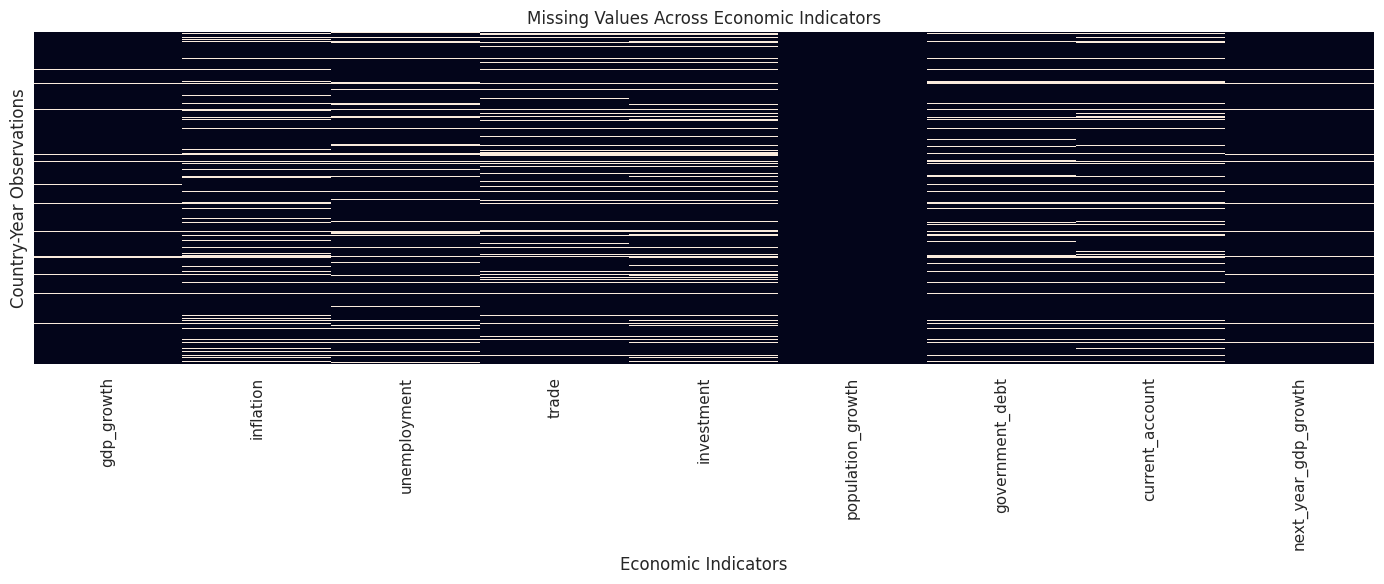

In [7]:
plt.figure(figsize=(14, 6))
sns.heatmap(
    eda_data[analysis_columns].isna(),
    cbar=False,
    yticklabels=False
)
plt.title("Missing Values Across Economic Indicators")
plt.xlabel("Economic Indicators")
plt.ylabel("Country-Year Observations")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"eda_figure_{len(os.listdir(output_dir)) + 1:02d}.png"), dpi=300, bbox_inches="tight")
plt.show()

## Duplicate record checks and Country coverage

This section completes the corresponding EDA and statistical analysis step.

In [8]:
exact_duplicates = int(eda_data.duplicated().sum())
duplicate_country_year = int(
    eda_data.duplicated(subset=["Country Code", "Year"]).sum()
)

print("Exact duplicate records:", exact_duplicates)
print("Duplicate country-year combinations:", duplicate_country_year)

country_coverage = (
    eda_data.groupby(["Country Code", "Country Name"])
    .size()
    .sort_values(ascending=False)
)

print("Total unique countries:", eda_data["Country Code"].nunique())
print("Top 10 countries by observations:")
display(country_coverage.head(10).to_frame("Observations"))
print("Bottom 10 countries by observations:")
display(country_coverage.tail(10).to_frame("Observations"))

Exact duplicate records: 0
Duplicate country-year combinations: 0
Total unique countries: 217
Top 10 countries by observations:


,,Observations
Country Code,Country Name,
ABW,Aruba,24
AFG,Afghanistan,24
AGO,Angola,24
ALB,Albania,24
AND,Andorra,24
ARE,United Arab Emirates,24
ARG,Argentina,24
ARM,Armenia,24
ASM,American Samoa,24


Bottom 10 countries by observations:


,,Observations
Country Code,Country Name,
VGB,British Virgin Islands,24
VIR,Virgin Islands (U.S.),24
VNM,Viet Nam,24
VUT,Vanuatu,24
WSM,Samoa,24
XKX,Kosovo,24
YEM,"Yemen, Rep.",24
ZAF,South Africa,24
ZMB,Zambia,24


## Input-year and target-year coverage and Year coverage visualisation

This section completes the corresponding EDA and statistical analysis step.

Minimum input year: 2000
Maximum input year: 2023
Minimum target year: 2001
Maximum target year: 2024
Number of unique input years: 24
Number of unique target years: 24


,Observations
Year,
2000,217
2001,217
2002,217
2003,217
2004,217
2005,217
2006,217
2007,217
2008,217


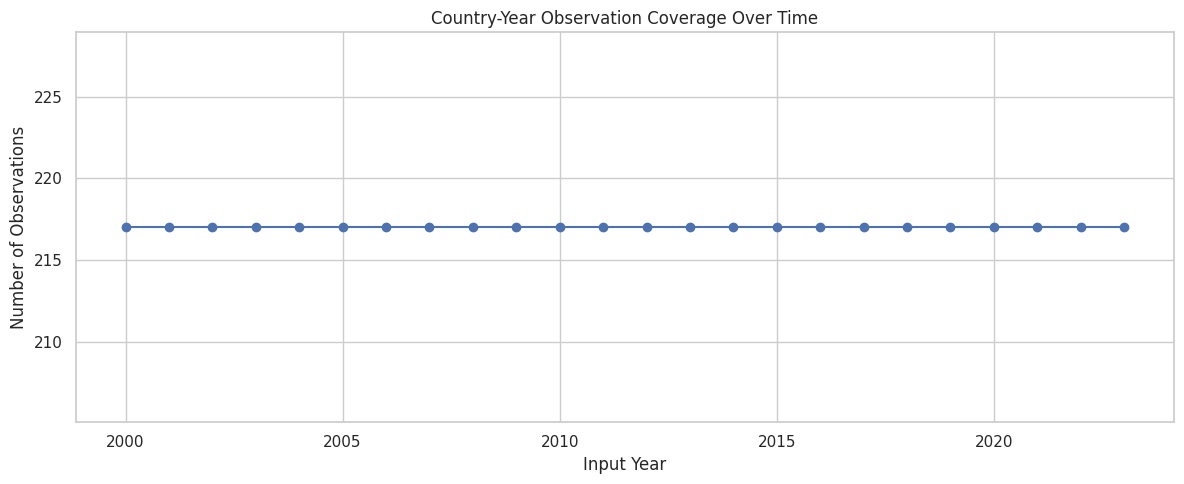

In [9]:
print("Minimum input year:", eda_data["Year"].min())
print("Maximum input year:", eda_data["Year"].max())
print("Minimum target year:", eda_data["target_year"].min())
print("Maximum target year:", eda_data["target_year"].max())
print("Number of unique input years:", eda_data["Year"].nunique())
print("Number of unique target years:", eda_data["target_year"].nunique())

year_coverage = eda_data.groupby("Year").size().sort_index()
display(year_coverage.to_frame("Observations"))

plt.figure(figsize=(12, 5))
plt.plot(year_coverage.index, year_coverage.values, marker="o")
plt.title("Country-Year Observation Coverage Over Time")
plt.xlabel("Input Year")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"eda_figure_{len(os.listdir(output_dir)) + 1:02d}.png"), dpi=300, bbox_inches="tight")
plt.show()

## Target-year alignment check

This section completes the corresponding EDA and statistical analysis step.

In [10]:
year_difference = eda_data["target_year"] - eda_data["Year"]
correct_alignment = int((year_difference == 1).sum())
incorrect_alignment = int((year_difference != 1).sum())

print("Correctly aligned observations:", correct_alignment)
print("Incorrectly aligned observations:", incorrect_alignment)

Correctly aligned observations: 5208
Incorrectly aligned observations: 0


## Descriptive statistics and Mean, median and mode

This section completes the corresponding EDA and statistical analysis step.

In [11]:
descriptive_stats = eda_data[analysis_columns].describe().T
display(descriptive_stats.round(3))

central_tendency = pd.DataFrame({
    "Mean": eda_data[analysis_columns].mean(),
    "Median": eda_data[analysis_columns].median(),
    "Mode": eda_data[analysis_columns].apply(
        lambda values: values.mode().iloc[0] if not values.mode().empty else np.nan
    )
})
display(central_tendency.round(3))

,count,mean,std,min,25%,50%,75%,max
gdp_growth,4968.0,3.335,6.028,-54.402,1.192,3.535,5.855,86.827
inflation,4352.0,6.716,19.929,-16.860,1.622,3.537,7.116,557.202
unemployment,4484.0,8.053,6.024,0.100,3.752,6.186,10.842,37.320
trade,4278.0,90.253,58.740,0.000,54.968,77.989,108.896,863.195
investment,4104.0,24.041,8.562,-15.678,19.043,23.114,27.952,76.782
population_growth,5207.0,1.294,1.612,-11.357,0.314,1.191,2.217,21.700
government_debt,4453.0,54.725,44.388,0.002,28.370,44.971,68.536,600.109
current_account,4485.0,-1.686,14.356,-84.851,-7.063,-2.523,2.278,314.906
next_year_gdp_growth,4969.0,3.280,5.982,-54.402,1.189,3.475,5.797,86.827


,Mean,Median,Mode
gdp_growth,3.335,3.535,0.000
inflation,6.716,3.537,-16.860
unemployment,8.053,6.186,0.870
trade,90.253,77.989,0.000
investment,24.041,23.114,0.000
population_growth,1.294,1.191,-11.357
government_debt,54.725,44.971,6.136
current_account,-1.686,-2.523,-4.670
next_year_gdp_growth,3.280,3.475,0.000


## Variance, standard deviation, range, skewness and kurtosis

This section completes the corresponding EDA and statistical analysis step.

In [12]:
distribution_summary = pd.DataFrame({
    "Variance": eda_data[analysis_columns].var(),
    "Standard Deviation": eda_data[analysis_columns].std(),
    "Range": eda_data[analysis_columns].max() - eda_data[analysis_columns].min(),
    "Skewness": eda_data[analysis_columns].skew(),
    "Kurtosis": eda_data[analysis_columns].kurtosis()
})
display(distribution_summary.round(3))

,Variance,Standard Deviation,Range,Skewness,Kurtosis
gdp_growth,36.334,6.028,141.229,0.954,30.328
inflation,397.175,19.929,574.062,16.043,338.397
unemployment,36.284,6.024,37.220,1.429,2.179
trade,3450.395,58.740,863.195,3.311,20.181
investment,73.300,8.562,92.461,0.832,3.140
population_growth,2.599,1.612,33.057,1.055,13.209
government_debt,1970.289,44.388,600.107,3.481,23.448
current_account,206.094,14.356,399.757,6.314,106.614
next_year_gdp_growth,35.784,5.982,141.229,0.862,30.381


## Mean values visualisation

Indicators have different units and scales, so this chart is descriptive rather than a direct comparison of importance.

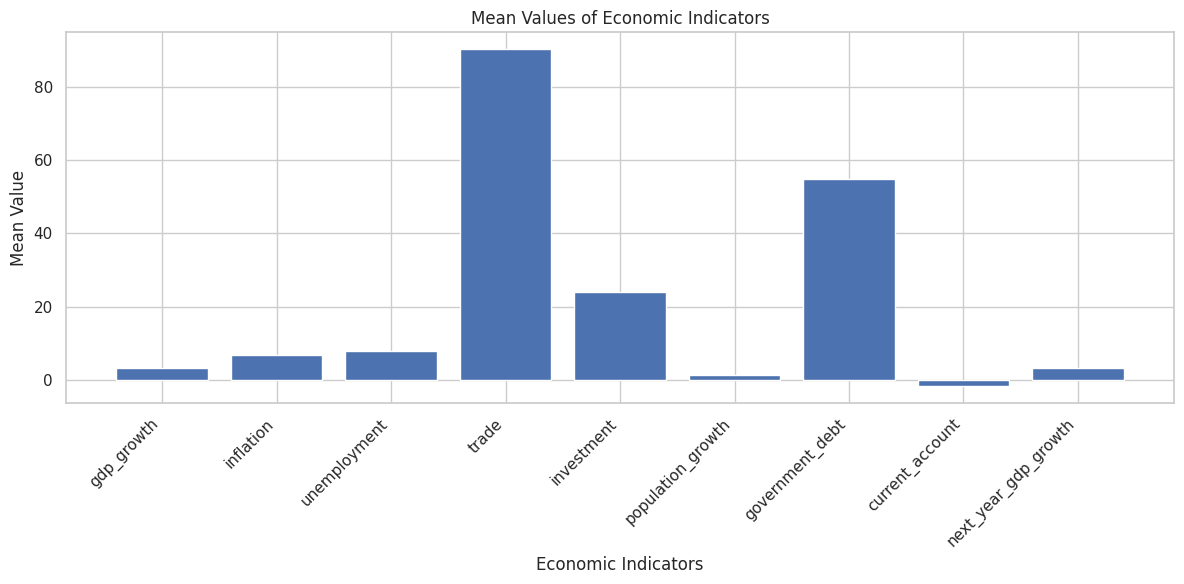

Note: Indicators use different units and scales, so their means should not be compared as if they were on the same scale.


In [13]:
mean_values = eda_data[analysis_columns].mean().dropna()
plt.figure(figsize=(12, 6))
plt.bar(mean_values.index, mean_values.values)
plt.title("Mean Values of Economic Indicators")
plt.xlabel("Economic Indicators")
plt.ylabel("Mean Value")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"eda_figure_{len(os.listdir(output_dir)) + 1:02d}.png"), dpi=300, bbox_inches="tight")
plt.show()

print("Note: Indicators use different units and scales, so their means should not be compared as if they were on the same scale.")

## Histograms

This section completes the corresponding EDA and statistical analysis step.

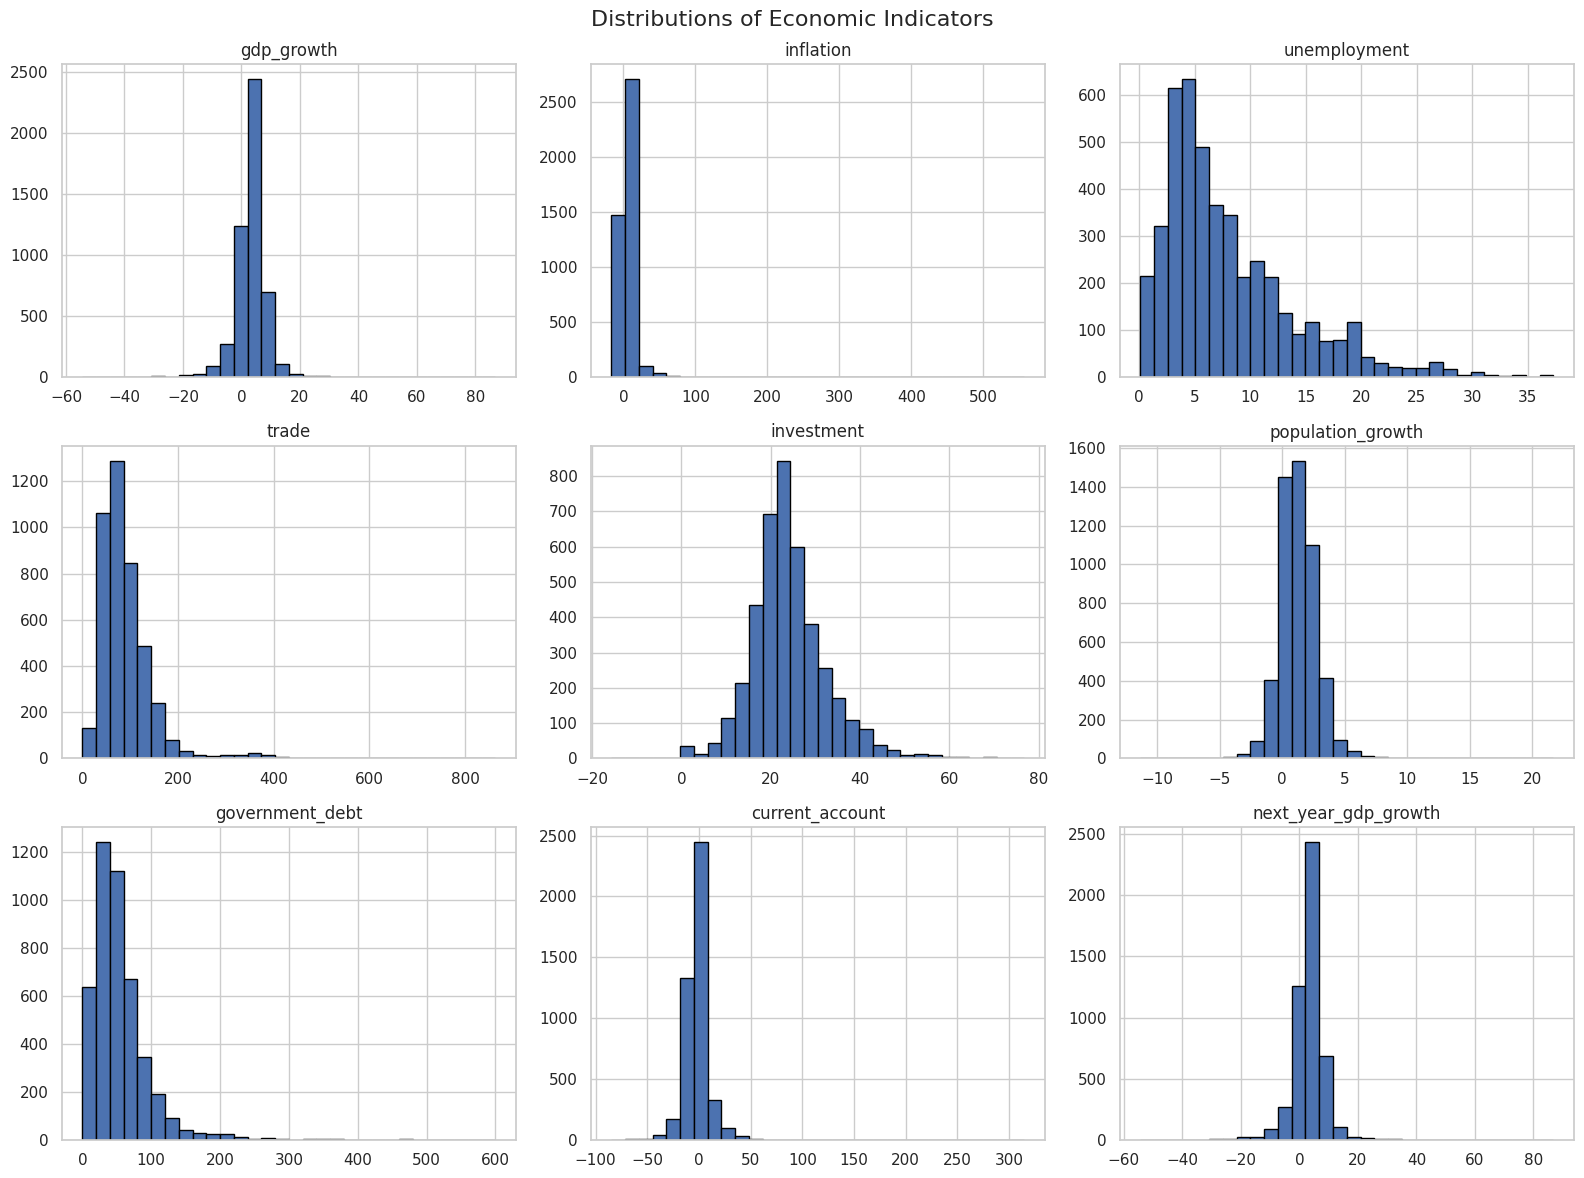

In [14]:
eda_data[analysis_columns].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)
plt.suptitle("Distributions of Economic Indicators", fontsize=16)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"eda_figure_{len(os.listdir(output_dir)) + 1:02d}.png"), dpi=300, bbox_inches="tight")
plt.show()

## Boxplots

This section completes the corresponding EDA and statistical analysis step.

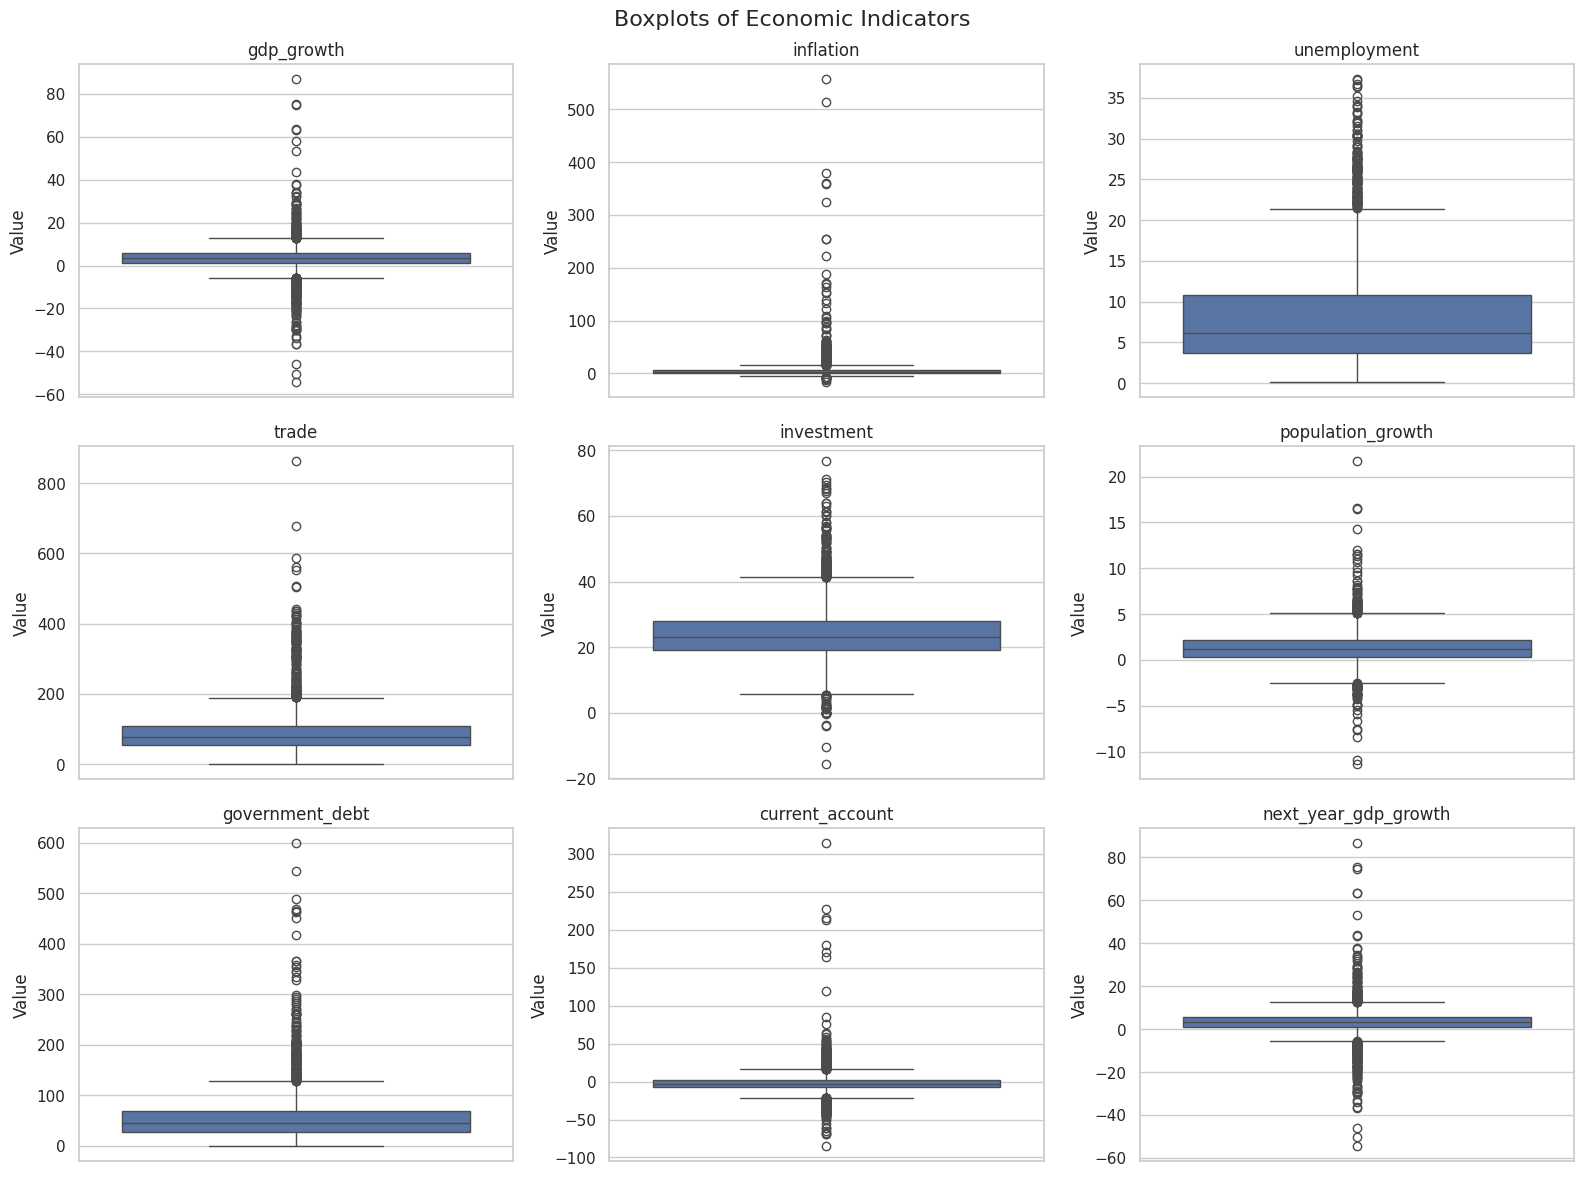

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for axis, column in zip(axes.flatten(), analysis_columns):
    values = eda_data[column].dropna()
    if not values.empty:
        sns.boxplot(y=values, ax=axis)
    axis.set_title(column)
    axis.set_ylabel("Value")
plt.suptitle("Boxplots of Economic Indicators", fontsize=16)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"eda_figure_{len(os.listdir(output_dir)) + 1:02d}.png"), dpi=300, bbox_inches="tight")
plt.show()

## IQR outlier analysis

The 1.5 × IQR rule identifies potential outliers for investigation; it does not prove that an observation is incorrect.

In [16]:
outlier_rows = []
for column in analysis_columns:
    values = eda_data[column].dropna()
    if values.empty:
        outlier_rows.append({
            "Indicator": column, "Valid Observations": 0,
            "Lower Bound": np.nan, "Upper Bound": np.nan,
            "Outlier Count": 0, "Outlier Percentage": np.nan
        })
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr_value = q3 - q1
    lower_bound = q1 - 1.5 * iqr_value
    upper_bound = q3 + 1.5 * iqr_value
    outlier_count = int(((values < lower_bound) | (values > upper_bound)).sum())

    outlier_rows.append({
        "Indicator": column,
        "Valid Observations": len(values),
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier Percentage": outlier_count / len(values) * 100
    })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary.round(3))

,Indicator,Valid Observations,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,gdp_growth,4968,-5.802,12.849,347,6.985
1,inflation,4352,-6.619,15.356,293,6.733
2,unemployment,4484,-6.882,21.476,165,3.680
3,trade,4278,-25.925,189.789,163,3.810
4,investment,4104,5.679,41.316,206,5.019
5,population_growth,5207,-2.542,5.073,126,2.420
6,government_debt,4453,-31.879,128.785,214,4.806
7,current_account,4485,-21.074,16.289,380,8.473
8,next_year_gdp_growth,4969,-5.722,12.708,348,7.003


## Outlier percentage visualisation

The 1.5 × IQR rule identifies potential outliers for investigation; it does not prove that an observation is incorrect.

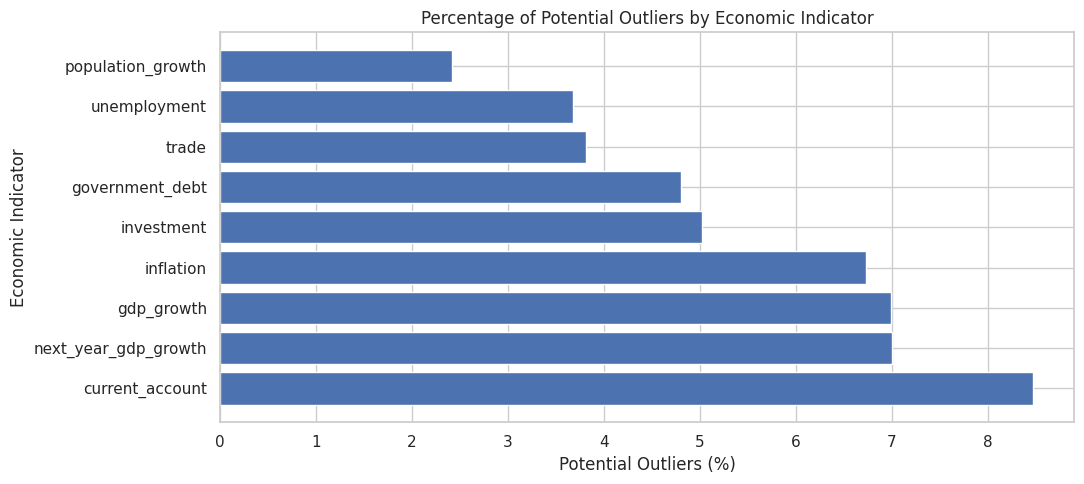

In [17]:
outlier_plot = outlier_summary.dropna(
    subset=["Outlier Percentage"]
).sort_values("Outlier Percentage", ascending=False)

plt.figure(figsize=(11, 5))
plt.barh(outlier_plot["Indicator"], outlier_plot["Outlier Percentage"])
plt.title("Percentage of Potential Outliers by Economic Indicator")
plt.xlabel("Potential Outliers (%)")
plt.ylabel("Economic Indicator")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"eda_figure_{len(os.listdir(output_dir)) + 1:02d}.png"), dpi=300, bbox_inches="tight")
plt.show()

## Inspect extreme observations

This section completes the corresponding EDA and statistical analysis step.

In [18]:
for column in analysis_columns:
    print(f"\nFive lowest observations for {column}")
    display(
        eda_data.nsmallest(5, column)[
            ["Country Code", "Country Name", "Year", column]
        ]
    )
    print(f"Five highest observations for {column}")
    display(
        eda_data.nlargest(5, column)[
            ["Country Code", "Country Name", "Year", column]
        ]
    )


Five lowest observations for gdp_growth


,Country Code,Country Name,Year,gdp_growth
4812,MAC,"Macao SAR, China",2020,-54.402093
1881,LBY,Libya,2011,-50.338515
3021,SSD,South Sudan,2012,-46.082122
1567,IRQ,Iraq,2003,-36.656780
540,CAF,Central African Republic,2013,-36.391977


Five highest observations for gdp_growth


,Country Code,Country Name,Year,gdp_growth
1882,LBY,Libya,2012,86.826748
4815,MAC,"Macao SAR, China",2023,75.308418
4063,TCA,Turks and Caicos Islands,2017,74.587988
1276,GNQ,Equatorial Guinea,2001,63.379875
4666,GUY,Guyana,2022,63.334634



Five lowest observations for inflation


,Country Code,Country Name,Year,inflation
1947,LSO,Lesotho,2009,-16.859691
880,DJI,Djibouti,2013,-12.563149
1571,IRQ,Iraq,2007,-10.067493
1872,LBY,Libya,2002,-9.797647
1939,LSO,Lesotho,2001,-9.616154


... (26 outputs left out)


Five lowest observations for next_year_gdp_growth


,Country Code,Country Name,Year,next_year_gdp_growth
4241,MAC,"Macao SAR, China",2019,-54.402093
1880,LBY,Libya,2010,-50.338515
3020,SSD,South Sudan,2011,-46.082122
1566,IRQ,Iraq,2002,-36.656780
539,CAF,Central African Republic,2012,-36.391977


Five highest observations for next_year_gdp_growth


,Country Code,Country Name,Year,next_year_gdp_growth
1881,LBY,Libya,2011,86.826748
4814,MAC,"Macao SAR, China",2022,75.308418
3195,TCA,Turks and Caicos Islands,2016,74.587988
1275,GNQ,Equatorial Guinea,2000,63.379875
4665,GUY,Guyana,2021,63.334634


## Pearson correlation matrix

Pearson correlation measures linear association. Correlation does not establish causation.

In [19]:
pearson_corr = eda_data[analysis_columns].corr(
    method="pearson",
    min_periods=3
)
display(pearson_corr.round(3))

,gdp_growth,inflation,unemployment,trade,investment,population_growth,government_debt,current_account,next_year_gdp_growth
gdp_growth,1.000,-0.063,-0.099,0.031,0.189,0.164,-0.109,0.075,0.214
inflation,-0.063,1.000,0.019,-0.096,-0.104,0.021,0.137,-0.027,-0.033
unemployment,-0.099,0.019,1.000,-0.005,-0.068,-0.194,0.046,-0.075,-0.047
trade,0.031,-0.096,-0.005,1.000,0.099,-0.111,-0.043,0.144,-0.017
investment,0.189,-0.104,-0.068,0.099,1.000,0.025,-0.149,-0.121,0.117
population_growth,0.164,0.021,-0.194,-0.111,0.025,1.000,-0.059,0.075,0.133
government_debt,-0.109,0.137,0.046,-0.043,-0.149,-0.059,1.000,-0.104,-0.053
current_account,0.075,-0.027,-0.075,0.144,-0.121,0.075,-0.104,1.000,0.006
next_year_gdp_growth,0.214,-0.033,-0.047,-0.017,0.117,0.133,-0.053,0.006,1.000


## Pearson correlation heatmap

Pearson correlation measures linear association. Correlation does not establish causation.

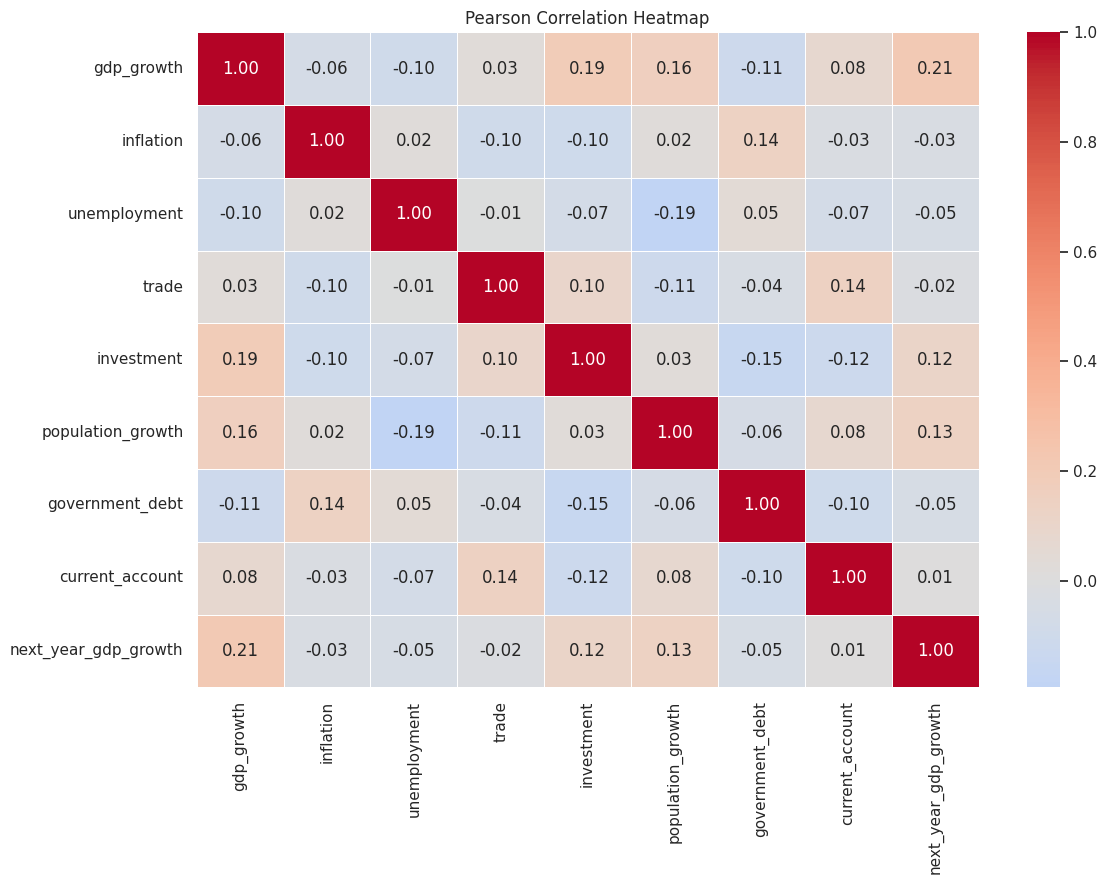

In [20]:
plt.figure(figsize=(12, 9))
sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)
plt.title("Pearson Correlation Heatmap")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"eda_figure_{len(os.listdir(output_dir)) + 1:02d}.png"), dpi=300, bbox_inches="tight")
plt.show()

## Correlations with next-year GDP growth

This section completes the corresponding EDA and statistical analysis step.

In [21]:
target_pearson = pearson_corr[target_column].drop(target_column)
target_pearson = target_pearson.reindex(
    target_pearson.abs().sort_values(ascending=False).index
)
display(
    target_pearson.to_frame(
        "Correlation with Next-Year GDP Growth"
    ).round(3)
)

,Correlation with Next-Year GDP Growth
gdp_growth,0.214
population_growth,0.133
investment,0.117
government_debt,-0.053
unemployment,-0.047
inflation,-0.033
trade,-0.017
current_account,0.006


## Visualise target correlations

This section completes the corresponding EDA and statistical analysis step.

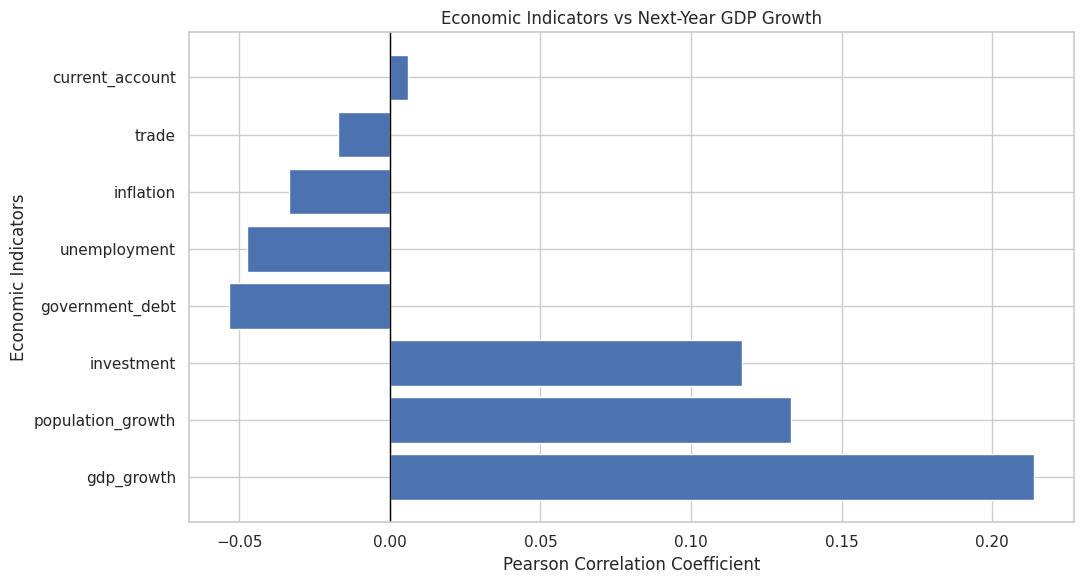

In [22]:
plt.figure(figsize=(11, 6))
plt.barh(target_pearson.index, target_pearson.values)
plt.axvline(0, color="black", linewidth=1)
plt.title("Economic Indicators vs Next-Year GDP Growth")
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Economic Indicators")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"eda_figure_{len(os.listdir(output_dir)) + 1:02d}.png"), dpi=300, bbox_inches="tight")
plt.show()

## Spearman correlation matrix

Spearman correlation measures rank-based monotonic association.

In [23]:
spearman_corr = eda_data[analysis_columns].corr(
    method="spearman",
    min_periods=3
)
display(spearman_corr.round(3))

,gdp_growth,inflation,unemployment,trade,investment,population_growth,government_debt,current_account,next_year_gdp_growth
gdp_growth,1.000,0.158,-0.148,0.005,0.227,0.209,-0.161,-0.027,0.428
inflation,0.158,1.000,0.006,-0.164,0.028,0.146,-0.077,-0.149,0.090
unemployment,-0.148,0.006,1.000,0.034,-0.046,-0.256,0.136,-0.080,-0.097
trade,0.005,-0.164,0.034,1.000,0.214,-0.229,-0.050,0.101,-0.047
investment,0.227,0.028,-0.046,0.214,1.000,-0.043,-0.172,-0.174,0.122
population_growth,0.209,0.146,-0.256,-0.229,-0.043,1.000,-0.138,-0.008,0.193
government_debt,-0.161,-0.077,0.136,-0.050,-0.172,-0.138,1.000,-0.129,-0.082
current_account,-0.027,-0.149,-0.080,0.101,-0.174,-0.008,-0.129,1.000,-0.022
next_year_gdp_growth,0.428,0.090,-0.097,-0.047,0.122,0.193,-0.082,-0.022,1.000


## Compare Pearson and Spearman correlations

Pearson correlation measures linear association. Correlation does not establish causation.

In [24]:
target_spearman = spearman_corr[target_column].drop(target_column)
correlation_comparison = pd.DataFrame({
    "Pearson": target_pearson,
    "Spearman": target_spearman
})
display(correlation_comparison.round(3))

,Pearson,Spearman
current_account,0.006,-0.022
gdp_growth,0.214,0.428
government_debt,-0.053,-0.082
inflation,-0.033,0.090
investment,0.117,0.122
population_growth,0.133,0.193
trade,-0.017,-0.047
unemployment,-0.047,-0.097


## Pearson hypothesis testing

The null hypothesis is that the predictor has no correlation with next-year GDP growth. Pairwise complete observations are used.

In [25]:
def run_correlation_tests(data, predictors, target, method):
    rows = []
    for variable in predictors:
        if variable == target:
            continue

        sample = data[[variable, target]].dropna()
        sample_size = len(sample)

        if (
            sample_size < 3
            or sample[variable].nunique() < 2
            or sample[target].nunique() < 2
        ):
            coefficient, p_value = np.nan, np.nan
        elif method == "pearson":
            coefficient, p_value = stats.pearsonr(
                sample[variable], sample[target]
            )
        else:
            coefficient, p_value = stats.spearmanr(
                sample[variable], sample[target]
            )

        rows.append({
            "Indicator": variable,
            "Correlation": coefficient,
            "P-Value": p_value,
            "Sample Size": sample_size
        })

    return pd.DataFrame(rows)

pearson_tests = run_correlation_tests(
    eda_data, analysis_columns, target_column, "pearson"
)
display(pearson_tests.round(6))

,Indicator,Correlation,P-Value,Sample Size
0,gdp_growth,0.213828,0.000000,4953
1,inflation,-0.033352,0.028448,4316
2,unemployment,-0.047499,0.001677,4374
3,trade,-0.017334,0.258949,4243
4,investment,0.117078,0.000000,4074
5,population_growth,0.133249,0.000000,4968
6,government_debt,-0.053355,0.000390,4415
7,current_account,0.006107,0.684511,4429


## Spearman hypothesis testing

The null hypothesis is that the predictor has no correlation with next-year GDP growth. Pairwise complete observations are used.

In [26]:
spearman_tests = run_correlation_tests(
    eda_data, analysis_columns, target_column, "spearman"
)
display(spearman_tests.round(6))

,Indicator,Correlation,P-Value,Sample Size
0,gdp_growth,0.428162,0.000000,4953
1,inflation,0.090201,0.000000,4316
2,unemployment,-0.097499,0.000000,4374
3,trade,-0.046980,0.002206,4243
4,investment,0.121912,0.000000,4074
5,population_growth,0.192805,0.000000,4968
6,government_debt,-0.081539,0.000000,4415
7,current_account,-0.022407,0.135964,4429


## Multiple-testing correction and significance

Benjamini–Hochberg false discovery rate correction is applied separately to Pearson and Spearman p-values.

In [27]:
for results in [pearson_tests, spearman_tests]:
    results["Adjusted P-Value"] = np.nan
    valid_p_values = results["P-Value"].notna()

    if valid_p_values.any():
        results.loc[valid_p_values, "Adjusted P-Value"] = multipletests(
            results.loc[valid_p_values, "P-Value"],
            method="fdr_bh"
        )[1]

    results["Significant at 5%"] = results["Adjusted P-Value"] < 0.05

print("Pearson results after Benjamini-Hochberg correction:")
display(pearson_tests.round(6))
print("Spearman results after Benjamini-Hochberg correction:")
display(spearman_tests.round(6))

Pearson results after Benjamini-Hochberg correction:


,Indicator,Correlation,P-Value,Sample Size,Adjusted P-Value,Significant at 5%
0,gdp_growth,0.213828,0.000000,4953,0.000000,True
1,inflation,-0.033352,0.028448,4316,0.037930,True
2,unemployment,-0.047499,0.001677,4374,0.002682,True
3,trade,-0.017334,0.258949,4243,0.295942,False
4,investment,0.117078,0.000000,4074,0.000000,True
5,population_growth,0.133249,0.000000,4968,0.000000,True
6,government_debt,-0.053355,0.000390,4415,0.000780,True
7,current_account,0.006107,0.684511,4429,0.684511,False


Spearman results after Benjamini-Hochberg correction:


,Indicator,Correlation,P-Value,Sample Size,Adjusted P-Value,Significant at 5%
0,gdp_growth,0.428162,0.000000,4953,0.000000,True
1,inflation,0.090201,0.000000,4316,0.000000,True
2,unemployment,-0.097499,0.000000,4374,0.000000,True
3,trade,-0.046980,0.002206,4243,0.002521,True
4,investment,0.121912,0.000000,4074,0.000000,True
5,population_growth,0.192805,0.000000,4968,0.000000,True
6,government_debt,-0.081539,0.000000,4415,0.000000,True
7,current_account,-0.022407,0.135964,4429,0.135964,False


## Country-level GDP growth

This section completes the corresponding EDA and statistical analysis step.

In [28]:
country_gdp = (
    eda_data.groupby(["Country Code", "Country Name"])["gdp_growth"]
    .agg(Average_GDP_Growth="mean", Observations="count")
    .dropna(subset=["Average_GDP_Growth"])
    .sort_values("Average_GDP_Growth", ascending=False)
)
display(country_gdp.round(3))

,,Average_GDP_Growth,Observations
Country Code,Country Name,,
GUY,Guyana,9.057,24
ETH,Ethiopia,8.434,24
CHN,China,8.326,24
TCA,Turks and Caicos Islands,8.123,16
TKM,Turkmenistan,7.747,24
...,...,...,...
VIR,Virgin Islands (U.S.),-0.800,20
MAF,St. Martin (French part),-1.586,7
MNP,Northern Mariana Islands,-1.929,20


## Top 10 countries by average GDP growth

This section completes the corresponding EDA and statistical analysis step.

,,Average_GDP_Growth,Observations
Country Code,Country Name,,
GUY,Guyana,9.057,24
ETH,Ethiopia,8.434,24
CHN,China,8.326,24
TCA,Turks and Caicos Islands,8.123,16
TKM,Turkmenistan,7.747,24
TJK,Tajikistan,7.664,24
AZE,Azerbaijan,7.559,24
MMR,Myanmar,7.454,24
RWA,Rwanda,7.428,24


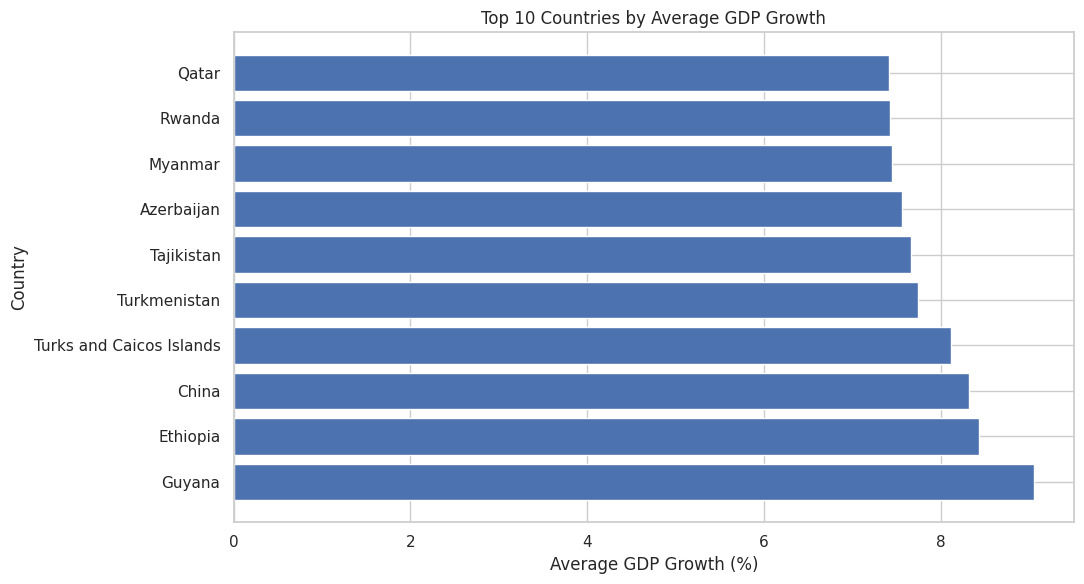

In [29]:
top_countries = country_gdp.head(10)
display(top_countries.round(3))

plt.figure(figsize=(11, 6))
plt.barh(
    top_countries.reset_index()["Country Name"],
    top_countries.reset_index()["Average_GDP_Growth"]
)
plt.title("Top 10 Countries by Average GDP Growth")
plt.xlabel("Average GDP Growth (%)")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"eda_figure_{len(os.listdir(output_dir)) + 1:02d}.png"), dpi=300, bbox_inches="tight")
plt.show()

## Bottom 10 countries by average GDP growth

This section completes the corresponding EDA and statistical analysis step.

,,Average_GDP_Growth,Observations
Country Code,Country Name,,
SSD,South Sudan,-4.925,7
VEN,"Venezuela, RB",-2.417,24
MNP,Northern Mariana Islands,-1.929,20
MAF,St. Martin (French part),-1.586,7
VIR,Virgin Islands (U.S.),-0.800,20
SYR,Syrian Arab Republic,-0.605,23
ASM,American Samoa,-0.542,20
CUW,Curacao,-0.206,23
PLW,Palau,-0.050,24


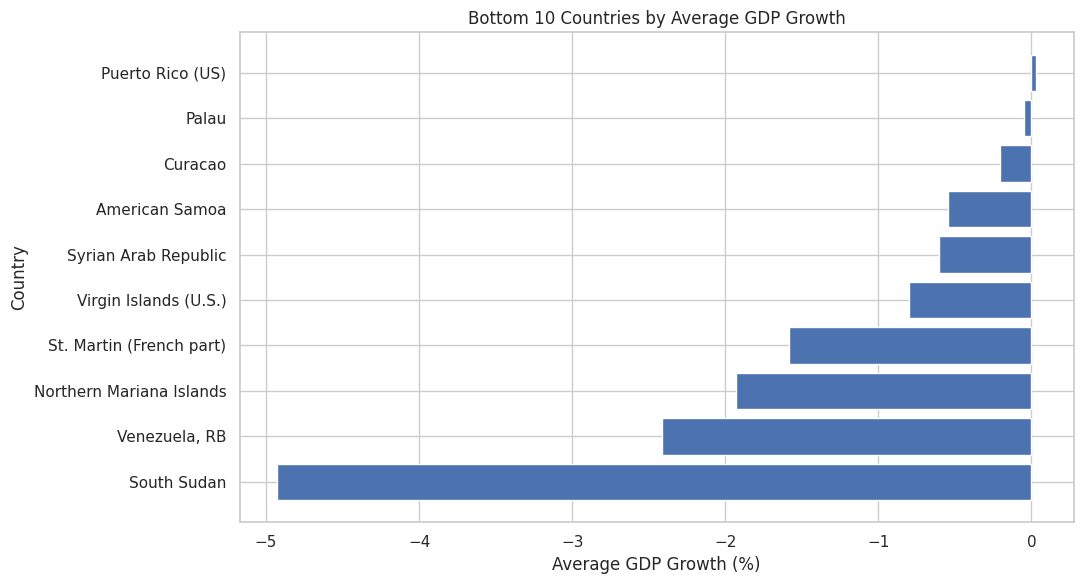

In [30]:
bottom_countries = country_gdp.tail(10).sort_values(
    "Average_GDP_Growth"
)
display(bottom_countries.round(3))

plt.figure(figsize=(11, 6))
plt.barh(
    bottom_countries.reset_index()["Country Name"],
    bottom_countries.reset_index()["Average_GDP_Growth"]
)
plt.title("Bottom 10 Countries by Average GDP Growth")
plt.xlabel("Average GDP Growth (%)")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"eda_figure_{len(os.listdir(output_dir)) + 1:02d}.png"), dpi=300, bbox_inches="tight")
plt.show()

## Yearly GDP growth trend

This section completes the corresponding EDA and statistical analysis step.

,Average_GDP_Growth,Country_Observations
Year,,
2000,4.512,199
2001,3.293,200
2002,3.358,200
2003,3.804,204
2004,5.775,204
2005,4.961,204
2006,5.679,204
2007,5.470,205
2008,3.733,206


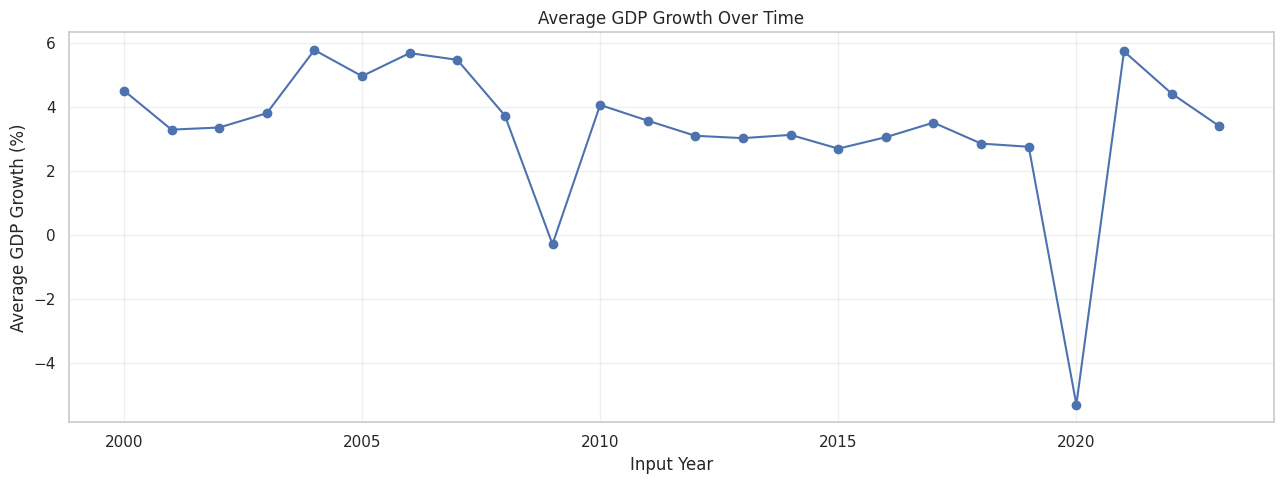

In [31]:
yearly_gdp = eda_data.groupby("Year")["gdp_growth"].agg(
    Average_GDP_Growth="mean",
    Country_Observations="count"
)
display(yearly_gdp.round(3))

plt.figure(figsize=(13, 5))
plt.plot(
    yearly_gdp.index,
    yearly_gdp["Average_GDP_Growth"],
    marker="o"
)
plt.title("Average GDP Growth Over Time")
plt.xlabel("Input Year")
plt.ylabel("Average GDP Growth (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"eda_figure_{len(os.listdir(output_dir)) + 1:02d}.png"), dpi=300, bbox_inches="tight")
plt.show()

## Selected country GDP growth trends

This section completes the corresponding EDA and statistical analysis step.

Country Name,China,Ethiopia,Guyana,Turkmenistan,Turks and Caicos Islands
Year,,,,,
2000,8.574,6.073,-1.364,5.469,NaN
2001,8.324,8.301,2.280,4.344,NaN
2002,9.236,1.515,1.133,0.257,NaN
2003,10.114,-2.161,-0.632,3.269,NaN
2004,10.140,13.573,1.563,5.000,NaN
2005,11.454,11.819,-1.951,13.034,NaN
2006,12.675,10.835,5.130,10.973,NaN
2007,14.151,11.456,7.191,11.059,NaN
2008,9.669,10.789,1.755,14.700,8.272


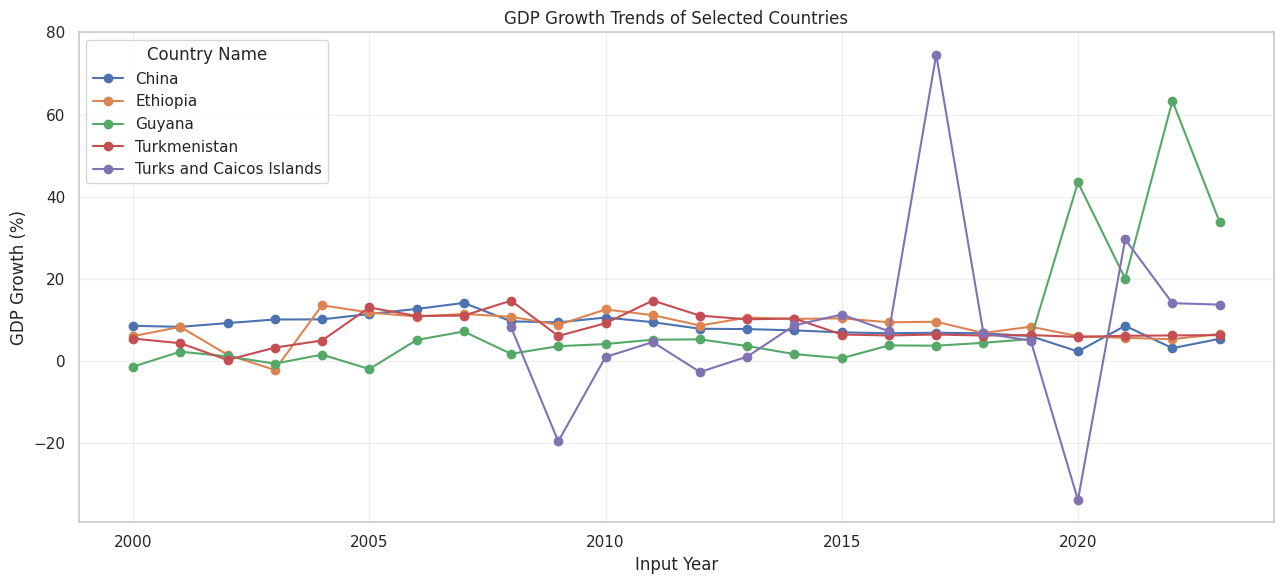

In [32]:
selected_countries = (
    top_countries.head(5).reset_index()["Country Name"].tolist()
)
selected_data = eda_data[
    eda_data["Country Name"].isin(selected_countries)
]

country_yearly = selected_data.pivot_table(
    index="Year",
    columns="Country Name",
    values="gdp_growth",
    aggfunc="mean"
)

if not country_yearly.empty:
    display(country_yearly.round(3))
    country_yearly.plot(figsize=(13, 6), marker="o")
    plt.title("GDP Growth Trends of Selected Countries")
    plt.xlabel("Input Year")
    plt.ylabel("GDP Growth (%)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, f"eda_figure_{len(os.listdir(output_dir)) + 1:02d}.png"), dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("No country trend data is available for the selected countries.")

## Final EDA integrity checks

The final summary checks dataset dimensions, target coverage, duplicate keys, year alignment and split sizes.

In [33]:
print("FINAL EDA SUMMARY")
print("=" * 45)
print("Total observations:", len(eda_data))
print("Total variables:", eda_data.shape[1])
print("Unique countries:", eda_data["Country Code"].nunique())
print("Input-year range:", eda_data["Year"].min(), "to", eda_data["Year"].max())
print("Target-year range:", eda_data["target_year"].min(), "to", eda_data["target_year"].max())
print("Non-missing next-year GDP growth:", int(eda_data[target_column].notna().sum()))
print("Missing next-year GDP growth:", int(eda_data[target_column].isna().sum()))
print("Target coverage (%):", round(eda_data[target_column].notna().mean() * 100, 2))
print("Exact duplicate rows:", int(eda_data.duplicated().sum()))
print(
    "Duplicate country-year keys:",
    int(eda_data.duplicated(subset=["Country Code", "Year"]).sum())
)
print(
    "Correct target-year alignments:",
    int((eda_data["target_year"] - eda_data["Year"] == 1).sum())
)
print(
    "Incorrect target-year alignments:",
    int((eda_data["target_year"] - eda_data["Year"] != 1).sum())
)
print("Observations by split:")
display(eda_data["dataset_split"].value_counts().to_frame("Observations"))

FINAL EDA SUMMARY
Total observations: 5208
Total variables: 14
Unique countries: 217
Input-year range: 2000 to 2023
Target-year range: 2001 to 2024
Non-missing next-year GDP growth: 4969
Missing next-year GDP growth: 239
Target coverage (%): 95.41
Exact duplicate rows: 0
Duplicate country-year keys: 0
Correct target-year alignments: 5208
Incorrect target-year alignments: 0
Observations by split:


,Observations
dataset_split,
Training,3689
Testing,868
Validation,434
COVID,217


## Interpretation and limitations

Use the executed results to write the findings for the group report. Discuss missing-data patterns, country coverage, year alignment, distributions, outliers, the strongest positive and negative correlations, statistical significance after FDR correction, and country-level trends.

Correlation does not establish causation. IQR outliers are flags for investigation rather than automatic errors. Unequal country coverage and missing observations may affect comparisons. Model fitting, preprocessing decisions and model tuning belong in the modelling workflow.

# EDA and Statistical Analysis – Interpretation of Findings

This section summarises the results produced by the prepared country-year dataset. The numerical findings below are taken from the saved outputs of the original executed EDA notebook for the same four dataset splits. Re-run this final notebook on the project ZIP and confirm that its outputs match before using these figures in the final report.

**Dataset overview:** The four splits contain 3,689 training observations, 434 validation observations, 217 COVID-2020 observations and 868 testing observations, giving 5,208 country-year records in total. The combined dataset contains 217 countries and 14 columns, including the dataset-split label.

## Missing Value Analysis

The missing-value analysis shows that **investment** has the highest missingness, with 1,104 missing observations (21.20%). This is followed by trade with 930 (17.86%), inflation with 856 (16.44%), government debt with 755 (14.50%), unemployment with 724 (13.90%) and current account with 723 (13.88%). GDP growth has 240 missing values (4.61%), while next-year GDP growth has 239 (4.59%). Population growth has only one missing value (0.02%). The country identifiers, year fields and dataset-split label contain no missing values.

This indicates that missingness is concentrated in several economic indicators rather than in the country and time identifiers. Investment and trade require particular attention during preprocessing. Missing values should be handled using a method fitted on the training data only, to avoid information leakage into validation and test periods.

## Country and Year Coverage

The combined dataset contains **5,208 observations across 217 countries**. Each country has 24 input-year observations, covering **2000–2023**, with corresponding target years from **2001–2024**. The saved coverage output reports 24 observations for every country, a minimum and maximum of 24 observations per country, and **zero duplicate country-year records**.

All 5,208 records were reported as having correctly aligned target years, with zero incorrect alignments. This provides consistent country-year coverage in the prepared dataset. However, indicator-level missing values still mean that not every country-year record has complete information for every feature.

## Descriptive Statistical Analysis

The average current-year GDP growth is **3.34%**, while the average next-year GDP growth target is **3.28%**. The median values are 3.53% and 3.48%, respectively. Average inflation is 6.72%, unemployment is 8.05%, trade is 90.25, investment is 24.04, population growth is 1.29%, government debt is 54.73 and current account balance is -1.69 (in the dataset's recorded units).

The standard deviation of inflation is relatively high at **19.93**, compared with 6.03 for current GDP growth and 5.98 for next-year GDP growth. This indicates substantial variation in inflation across country-year observations. For several variables, the mean and median differ, suggesting skewed distributions and the influence of extreme observations. The results should therefore be interpreted alongside the distribution plots and outlier analysis.

## Distribution and Outlier Analysis

The distribution analysis shows pronounced positive skewness for several indicators. Inflation has particularly high skewness (**16.04**) and kurtosis (**338.40**), indicating a highly asymmetric distribution with extreme values. Current account also has substantial positive skewness (6.31), while government debt (3.48) and trade (3.31) are positively skewed.

Using the IQR method, current account has the highest potential outlier percentage (**8.47%**), followed by next-year GDP growth (7.00%), current GDP growth (6.98%) and inflation (6.73%). Investment has 5.02%, government debt 4.81%, trade 3.81%, unemployment 3.68% and population growth 2.42% potential outliers.

These observations should not automatically be removed. Very high inflation or unusually low GDP growth may represent genuine economic crises or unusual events. The modelling team should inspect influential observations and document any treatment rather than deleting them solely because they fall outside the IQR bounds.

## Correlation Analysis

The Pearson correlations with next-year GDP growth show the strongest positive association for current-year GDP growth (**r = 0.214**), followed by population growth (**r = 0.133**) and investment (**r = 0.117**). The strongest negative associations are government debt (**r = -0.053**), unemployment (**r = -0.047**) and inflation (**r = -0.033**). Trade has a small negative correlation (**r = -0.017**), while current account has a very small positive correlation (**r = 0.006**).

The Spearman correlation between current GDP growth and next-year GDP growth is higher (**ρ = 0.428**) than its Pearson correlation, suggesting a stronger monotonic rank association than linear association. Population growth (ρ = 0.193) and investment (ρ = 0.122) also have positive Spearman associations. Overall, most correlations are weak in magnitude, so these indicators should not be treated as strong individual predictors based on correlation alone. Correlation does not establish causation.

## Hypothesis Testing and FDR Correction

Pearson and Spearman correlation tests were conducted for the eight economic indicators, using a 0.05 significance level and Benjamini–Hochberg False Discovery Rate correction. After FDR correction, **6 of the 8 Pearson relationships** were statistically significant: current GDP growth, inflation, unemployment, investment, population growth and government debt. Trade and current account were not statistically significant in the Pearson tests.

For the Spearman tests, **7 of the 8 relationships** were statistically significant after correction: current GDP growth, inflation, unemployment, trade, investment, population growth and government debt. Current account was not statistically significant.

Although several relationships are statistically significant, their correlation coefficients are generally small. Statistical significance can occur with large sample sizes and does not necessarily imply a practically strong relationship or predictive usefulness. The findings should be considered exploratory and interpreted alongside model-based evaluation.

## Country-Level and Yearly GDP Growth Analysis

Based on the saved country-average GDP growth results, the highest average values are observed for **Guyana (9.06%)**, Ethiopia (8.43%), China (8.33%), Turks and Caicos Islands (8.12%) and Turkmenistan (7.75%). The lowest reported averages among countries with available values are South Sudan (-4.93%), Venezuela, RB (-2.42%), Northern Mariana Islands (-1.93%), St. Martin (French part) (-1.59%) and the Virgin Islands (U.S.) (-0.80%). British Virgin Islands, Gibraltar and Korea, Dem. People's Rep. have no available average in the displayed output and are therefore not ranked by a numeric value.

The yearly averages show a sharp contraction in **2020 (-5.28%)**, followed by a strong rebound in **2021 (5.73%)**. Earlier, the average was also negative in 2009 (-0.28%). These patterns illustrate how major global shocks can affect aggregate growth and why time-aware validation is important for the forecasting task. Country averages should be interpreted with care because they summarise the available observations and do not explain the causes of each country's performance.

## Overall EDA Findings

The EDA identifies a dataset with broad and balanced country-year coverage: 5,208 observations across 217 countries and 24 input years, with no duplicate country-year keys and correct target-year alignment in the saved checks. However, some economic indicators have notable missingness, particularly investment, trade, inflation and government debt. Several variables are also strongly skewed and contain potential outliers, especially inflation and current account.

The correlation and hypothesis-testing results suggest that current-year GDP growth, population growth and investment have positive associations with next-year GDP growth, while government debt and unemployment have small negative associations. The relationships are mostly weak in magnitude, and statistical significance should not be confused with predictive performance.

These findings provide an evidence-based starting point for feature review and preprocessing. The machine learning team should compare models using the agreed time-based validation and test periods, fit preprocessing steps on training data only, and evaluate results against the persistence baseline and the IMF benchmark.

## Limitations of the EDA

This analysis is based on the prepared country-year dataset and the available observations for the selected indicators. Missing values may affect the sample size used in individual statistical tests, and the IQR method identifies potential outliers rather than proving that observations are erroneous. Extreme values may reflect genuine economic events.

Correlation and hypothesis tests identify associations, not causal effects. The analysis is exploratory and does not establish whether an indicator improves out-of-sample forecasting accuracy. Predictive value must be assessed through the project's time-based validation, holdout testing and comparison with the agreed baselines.

## Export and Download EDA Outputs

Run this final code cell after all analysis cells have executed. It exports the main statistical tables as CSV files, an Excel workbook, the combined EDA dataset, a text summary of key findings and all saved charts. It then downloads one ZIP archive containing the outputs.

In [34]:

import os
import zipfile
from datetime import datetime
from google.colab import files

os.makedirs(output_dir, exist_ok=True)

tables_to_export = {
    "dataset_dimensions": dataset_summary,
    "missing_values_summary": missing_summary,
    "missingness_by_split": split_missingness,
    "country_coverage": country_coverage.to_frame("Observations"),
    "year_coverage": year_coverage.to_frame("Observations"),
    "descriptive_statistics": descriptive_stats,
    "central_tendency": central_tendency,
    "distribution_statistics": distribution_summary,
    "outlier_summary": outlier_summary,
    "pearson_correlation_matrix": pearson_corr,
    "pearson_correlation_with_target": target_pearson.to_frame("Correlation with Next-Year GDP Growth"),
    "spearman_correlation_matrix": spearman_corr,
    "pearson_spearman_comparison": correlation_comparison,
    "pearson_hypothesis_tests_fdr": pearson_tests,
    "spearman_hypothesis_tests_fdr": spearman_tests,
    "country_average_gdp_growth": country_gdp,
    "top_10_countries": top_countries,
    "bottom_10_countries": bottom_countries,
    "yearly_gdp_growth": yearly_gdp
}

for filename, table in tables_to_export.items():
    table.to_csv(os.path.join(output_dir, f"{filename}.csv"), index=True)

eda_data.to_csv(os.path.join(output_dir, "combined_eda_dataset.csv"), index=False)

excel_path = os.path.join(output_dir, "EDA_Statistical_Results.xlsx")
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    for sheet_name, table in tables_to_export.items():
        safe_name = sheet_name[:31]
        table.to_excel(writer, sheet_name=safe_name)
    eda_data.head(1000).to_excel(writer, sheet_name="Combined_Data_Sample", index=False)

summary_lines = [
    "EDA AND STATISTICAL ANALYSIS – RESULTS SUMMARY",
    f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M')}",
    "",
    f"Total observations: {len(eda_data)}",
    f"Total variables: {eda_data.shape[1]}",
    f"Unique countries: {eda_data['Country Code'].nunique()}",
    f"Input-year range: {eda_data['Year'].min()} to {eda_data['Year'].max()}",
    f"Target-year range: {eda_data['target_year'].min()} to {eda_data['target_year'].max()}",
    f"Non-missing next-year GDP targets: {int(eda_data[target_column].notna().sum())}",
    f"Missing next-year GDP targets: {int(eda_data[target_column].isna().sum())}",
    f"Target coverage: {eda_data[target_column].notna().mean() * 100:.2f}%",
    f"Duplicate country-year keys: {int(eda_data.duplicated(subset=['Country Code', 'Year']).sum())}",
    f"Correct target-year alignments: {int((eda_data['target_year'] - eda_data['Year'] == 1).sum())}",
    f"Incorrect target-year alignments: {int((eda_data['target_year'] - eda_data['Year'] != 1).sum())}",
    "",
    "Missing values by variable:",
    missing_summary.round(2).to_string(),
    "",
    "Pearson correlation with next-year GDP growth:",
    target_pearson.round(4).to_string(),
    "",
    "Pearson tests after FDR correction:",
    pearson_tests.round(6).to_string(index=False),
    "",
    "Spearman tests after FDR correction:",
    spearman_tests.round(6).to_string(index=False),
    "",
    "Outlier summary:",
    outlier_summary.round(3).to_string(index=False),
    "",
    "Note: These are exploratory statistical results. Correlation does not establish causation."
]
summary_path = os.path.join(output_dir, "EDA_Findings_Summary.txt")
with open(summary_path, "w", encoding="utf-8") as f:
    f.write("\n".join(summary_lines))

# Create a single downloadable archive containing the tables, workbook, summary and charts.
zip_path = "/content/Sukesh_EDA_Statistical_Outputs.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for root, _, filenames in os.walk(output_dir):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            archive.write(full_path, arcname=os.path.relpath(full_path, output_dir))

print("EDA output files created:")
for filename in sorted(os.listdir(output_dir)):
    print("-", filename)
print("\nDownloading the complete EDA outputs ZIP...")
files.download(zip_path)


EDA output files created:
- EDA_Findings_Summary.txt
- EDA_Statistical_Results.xlsx
- bottom_10_countries.csv
- central_tendency.csv
- combined_eda_dataset.csv
- country_average_gdp_growth.csv
- country_coverage.csv
- dataset_dimensions.csv
- descriptive_statistics.csv
- distribution_statistics.csv
- eda_figure_01.png
- eda_figure_02.png
- eda_figure_03.png
- eda_figure_04.png
- eda_figure_05.png
- eda_figure_06.png
- eda_figure_07.png
- eda_figure_08.png
- eda_figure_09.png
- eda_figure_10.png
- eda_figure_11.png
- eda_figure_12.png
- missing_values_summary.csv
- missingness_by_split.csv
- outlier_summary.csv
- pearson_correlation_matrix.csv
- pearson_correlation_with_target.csv
- pearson_hypothesis_tests_fdr.csv
- pearson_spearman_comparison.csv
- spearman_correlation_matrix.csv
- spearman_hypothesis_tests_fdr.csv
- top_10_countries.csv
- year_coverage.csv
- yearly_gdp_growth.csv



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>